In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Fitting 5 folds for each of 1944 candidates, totalling 9720 fits
Best parameters found:  {'colsample_bytree': 0.5, 'eta': 0.01, 'gamma': 2, 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 300, 'reg_alpha': 0.5, 'reg_lambda': 1, 'scale_pos_weight': 1, 'subsample': 0.7}
Best AUC:  0.8250106186542414
[0]	validation_0-auc:0.79050	validation_0-error:0.48611	validation_0-logloss:0.68993	validation_1-auc:0.82789	validation_1-error:0.54167	validation_1-logloss:0.69252
[1]	validation_0-auc:0.81516	validation_0-error:0.48611	validation_0-logloss:0.68874	validation_1-auc:0.85215	validation_1-error:0.54167	validation_1-logloss:0.69131
[2]	validation_0-auc:0.80802	validation_0-error:0.48611	validation_0-logloss:0.68761	validation_1-auc:0.83518	validation_1-error:0.54167	validation_1-logloss:0.69009
[3]	validation_0-auc:0.80750	validation_0-error:0.48611	validation_0-logloss:0.68653	validation_1-auc:0.83610	validation_1-error:0.54167	validation_1-logloss:0.68880
[4]	validation_0-auc:0.81879	v

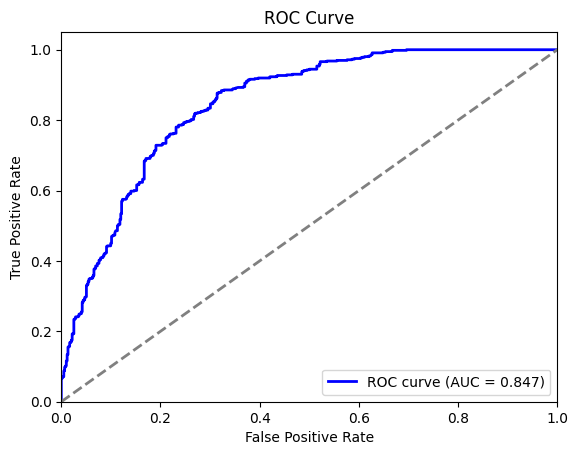

Confusion Matrix:
[[431 161]
 [101 459]]
Accuracy: 77.26%
Sensitivity (Recall): 81.96%
[[134  42]
 [ 34 150]]
              precision    recall  f1-score   support

           0       0.80      0.76      0.78       176
           1       0.78      0.82      0.80       184

    accuracy                           0.79       360
   macro avg       0.79      0.79      0.79       360
weighted avg       0.79      0.79      0.79       360



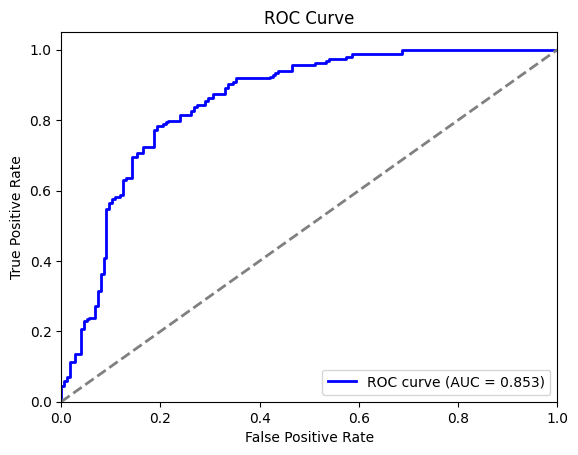

Confusion Matrix:
[[134  42]
 [ 34 150]]
Accuracy: 78.89%
Sensitivity (Recall): 81.52%


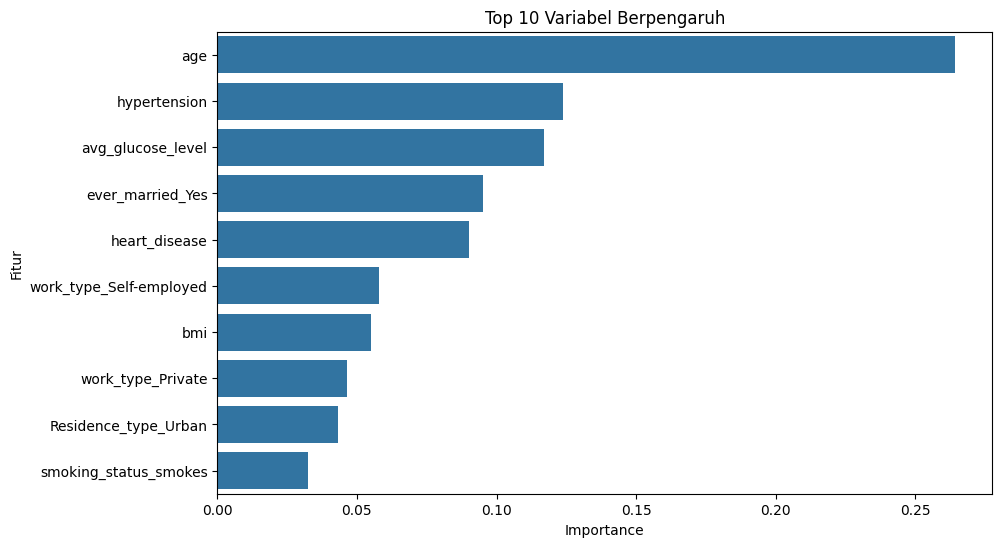

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

DRIVE_PATH =  '/content/drive/MyDrive/PROJECT SEMESTER 4/PSD/smote3.test.csv'

# Load and prepare data from Google Drive
data = pd.read_csv(DRIVE_PATH)

# Mengganti nilai "N/A" menjadi NaN dan membersihkan kolom
data = data.replace("N/A", pd.NA)
data['bmi'] = pd.to_numeric(data['bmi'], errors='coerce')

# Menghapus baris dengan nilai NaN
data = data.dropna()
data = data.drop(columns='Unnamed: 0')
data

from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
import random

random.seed(42)

# Pisahkan fitur (X) dan target (y)
X = data.drop(columns=['stroke'])
y = data['stroke']

# Sebelum split data
numeric_features = X.select_dtypes(include=['float64', 'int64']).columns
scaler = StandardScaler()
X[numeric_features] = scaler.fit_transform(X[numeric_features])

# Split data ke train dan test set (80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Pisahkan data training menjadi train dan validation
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

from sklearn.model_selection import GridSearchCV
import xgboost as xgb

# Model XGBoost untuk GridSearchCV
xgb_model = xgb.XGBClassifier(
    seed=42,
    eval_metric='auc'
)

# Grid search dengan parameter yang lebih ketat
param_grid = {
    'eta': [0.01, 0.005, 0.001],  # Learning rate yang lebih kecil
    'max_depth': [2],  # Kedalaman yang lebih terbatas
    'n_estimators': [100, 150, 300],
    'colsample_bytree': [0.3, 0.5, 0.7],
    'min_child_weight': [5, 7, 9],  # Nilai yang lebih tinggi
    'gamma': [2, 3],  # Nilai yang lebih tinggi untuk pruning
    'subsample': [0.5, 0.6, 0.7],
    'reg_alpha': [0.5, 1.0],  # L1 regularization yang lebih tinggi
    'reg_lambda': [1,2],  # L2 regularization yang lebih tinggi
    'scale_pos_weight': [1]  # Sesuaikan jika data tidak seimbang
}

# GridSearchCV
grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=5,
    verbose=1,
    n_jobs=-1  # Gunakan semua CPU cores
)

# Fit GridSearch
grid_search.fit(X_train, y_train)

# Print hasil terbaik
print("Best parameters found: ", grid_search.best_params_)
print("Best AUC: ", grid_search.best_score_)

# Buat model final dengan parameter terbaik
best_params = grid_search.best_params_
final_model = xgb.XGBClassifier(
    **best_params,
    seed=42,
    eval_metric=['auc', 'error', 'logloss'],
    early_stopping_rounds=20
)

# Fit model final
final_model.fit(
    X_train,
    y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=True
)

#Data Train
# Mengambil model terbaik dari Grid Search
best_xgb_model = grid_search.best_estimator_

# Prediksi probabilitas dan kelas
y_pred_prob = best_xgb_model.predict_proba(X_train)[:, 1]
y_pred_class = (y_pred_prob > 0.5).astype(int)

# Confusion Matrix
print(confusion_matrix(y_train, y_pred_class))

# Classification Report
print(classification_report(y_train, y_pred_class))

# Menghitung AUC dan plotting ROC curve
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

fpr, tpr, _ = roc_curve(y_train, y_pred_prob)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure()
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()


from sklearn.metrics import confusion_matrix, accuracy_score, recall_score

# Prediksi pada test set atau training set (misalnya X_test atau X_train)
y_pred = best_xgb_model.predict(X_train)  # Sesuaikan dengan data yang ingin digunakan (X_train atau X_test)

# Menghitung confusion matrix
conf_matrix = confusion_matrix(y_train, y_pred)

# Menghitung akurasi
accuracy = accuracy_score(y_train, y_pred)

# Menghitung sensitivitas (recall)
sensitivity = recall_score(y_train, y_pred)

# Menampilkan hasil
print("Confusion Matrix:")
print(conf_matrix)
print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"Sensitivity (Recall): {sensitivity * 100:.2f}%")


#Data Test
# Mengambil model terbaik dari Grid Search
best_xgb_model = grid_search.best_estimator_

# Prediksi probabilitas dan kelas
y_pred_prob = best_xgb_model.predict_proba(X_test)[:, 1]
y_pred_class = (y_pred_prob > 0.5).astype(int)

# Confusion Matrix
print(confusion_matrix(y_test, y_pred_class))

# Classification Report
print(classification_report(y_test, y_pred_class))

# Menghitung AUC dan plotting ROC curve
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure()
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()

from sklearn.metrics import confusion_matrix, accuracy_score, recall_score

# Prediksi pada test set atau training set (misalnya X_test atau X_train)
y_pred = best_xgb_model.predict(X_test)  # Sesuaikan dengan data yang ingin digunakan (X_train atau X_test)

# Menghitung confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Menghitung akurasi
accuracy = accuracy_score(y_test, y_pred)

# Menghitung sensitivitas (recall)
sensitivity = recall_score(y_test, y_pred)

# Menampilkan hasil
print("Confusion Matrix:")
print(conf_matrix)
print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"Sensitivity (Recall): {sensitivity * 100:.2f}%")



#Variable Importance
importance = best_xgb_model.feature_importances_
feature_importance_df = pd.DataFrame({'Fitur': X_train.columns, 'Importance': importance})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)
feature_importance_df

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Fitur', data=feature_importance_df.head(10))  # Menampilkan 10 fitur teratas
plt.title('Top 10 Variabel Berpengaruh')
plt.show()


Logistic Regression (Train) Confusion Matrix:
[[528 196]
 [139 577]]
Logistic Regression (Train) Accuracy: 76.74%
Logistic Regression (Train) Sensitivity (Recall): 80.59%


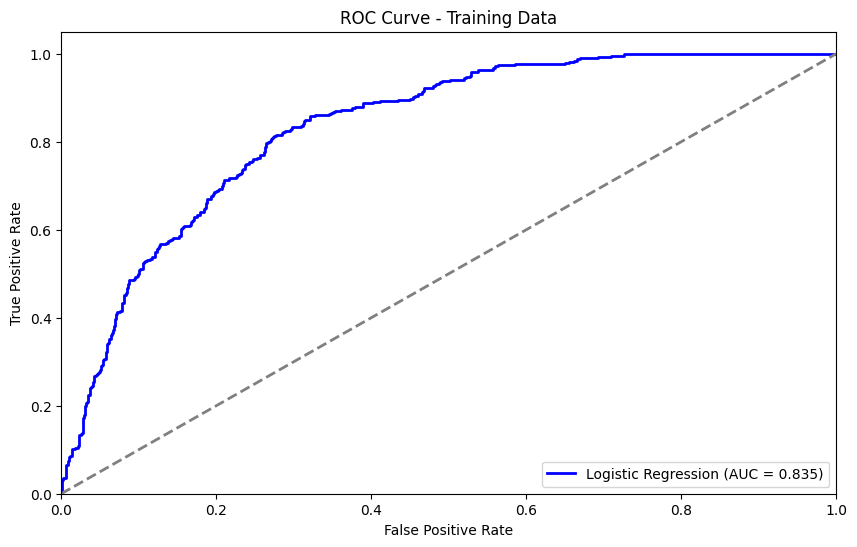

Logistic Regression (Test) Confusion Matrix:
[[135  41]
 [ 39 145]]
Logistic Regression (Test) Accuracy: 77.78%
Logistic Regression (Test) Sensitivity (Recall): 78.80%


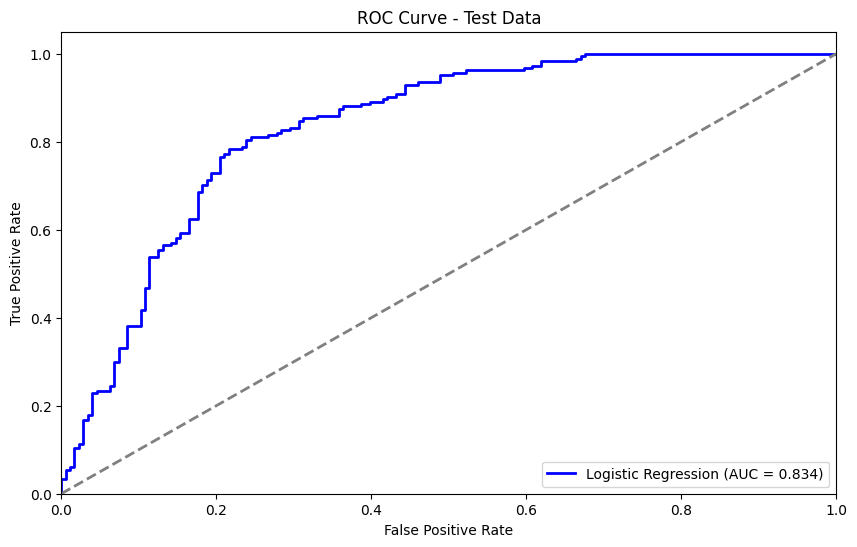


Logistic Regression (Test) Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.77      0.77       176
           1       0.78      0.79      0.78       184

    accuracy                           0.78       360
   macro avg       0.78      0.78      0.78       360
weighted avg       0.78      0.78      0.78       360


Feature Importance (Logistic Regression):
                             Fitur  Importance
11                             age    1.397898
0                     hypertension    0.317078
12               avg_glucose_level    0.298143
7                work_type_Private    0.232051
10           smoking_status_smokes    0.179821
1                    heart_disease    0.173089
9   smoking_status_formerly smoked    0.130308
2                    gender_Female    0.114029
4             Residence_type_Urban    0.072241
5               work_type_Govt_job    0.050581
8          work_type_Self-employed    0.025346
3              

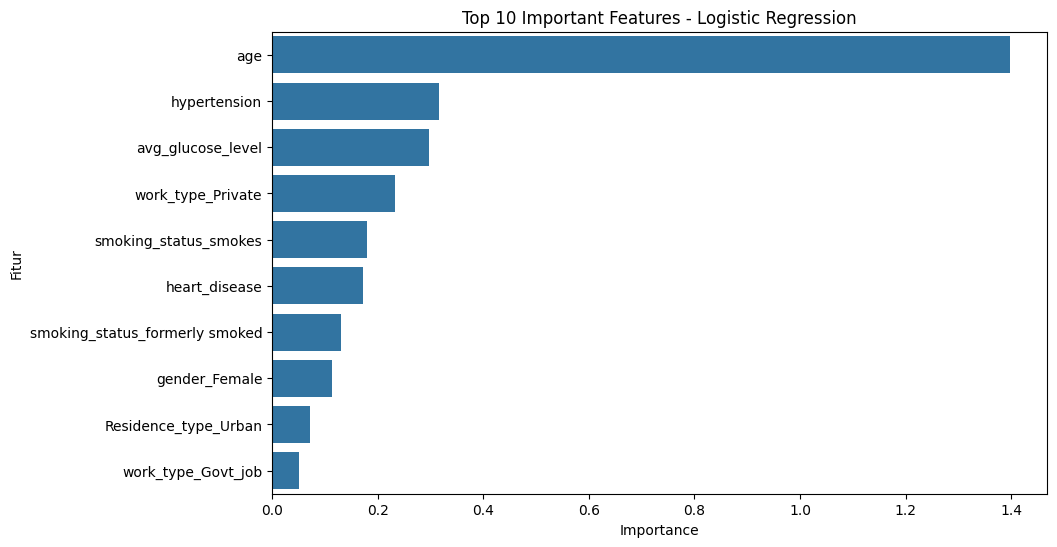

In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, classification_report, roc_curve, auc
import matplotlib.pyplot as plt
from imblearn.over_sampling import SMOTE
import random

# Set random seed
random.seed(42)

# Load and prepare data from Google Drive
DRIVE_PATH = '/content/drive/MyDrive/PROJECT SEMESTER 4/PSD/smote3.test.csv'
data = pd.read_csv(DRIVE_PATH)

# Replace "N/A" with NaN and clean columns
data = data.replace("N/A", pd.NA)
data['bmi'] = pd.to_numeric(data['bmi'], errors='coerce')

# Drop rows with NaN values
data = data.dropna()
data = data.drop(columns='Unnamed: 0')

# Separate features (X) and target (y)
X = data.drop(columns=['stroke'])
y = data['stroke']

# Standardize numerical features
numeric_features = X.select_dtypes(include=['float64', 'int64']).columns
scaler = StandardScaler()
X[numeric_features] = scaler.fit_transform(X[numeric_features])

# Split data into train and test sets (80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Logistic Regression Model
logreg_model = LogisticRegression(solver='liblinear', random_state=42)

# Fit Logistic Regression model
logreg_model.fit(X_train, y_train)

# Predictions on training data
y_pred_train = logreg_model.predict(X_train)
y_pred_prob_train = logreg_model.predict_proba(X_train)[:, 1]

# Confusion Matrix for Training Data
print("Logistic Regression (Train) Confusion Matrix:")
print(confusion_matrix(y_train, y_pred_train))
print(f"Logistic Regression (Train) Accuracy: {accuracy_score(y_train, y_pred_train) * 100:.2f}%")
print(f"Logistic Regression (Train) Sensitivity (Recall): {recall_score(y_train, y_pred_train) * 100:.2f}%")

# ROC curve for Training Data
fpr_train, tpr_train, _ = roc_curve(y_train, y_pred_prob_train)
roc_auc_train = auc(fpr_train, tpr_train)

plt.figure(figsize=(10, 6))
plt.plot(fpr_train, tpr_train, color='blue', lw=2, label=f'Logistic Regression (AUC = {roc_auc_train:.3f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Training Data')
plt.legend(loc="lower right")
plt.show()

# Predictions on Test Data
y_pred_test = logreg_model.predict(X_test)
y_pred_prob_test = logreg_model.predict_proba(X_test)[:, 1]

# Confusion Matrix for Test Data
print("Logistic Regression (Test) Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_test))
print(f"Logistic Regression (Test) Accuracy: {accuracy_score(y_test, y_pred_test) * 100:.2f}%")
print(f"Logistic Regression (Test) Sensitivity (Recall): {recall_score(y_test, y_pred_test) * 100:.2f}%")

# ROC curve for Test Data
fpr_test, tpr_test, _ = roc_curve(y_test, y_pred_prob_test)
roc_auc_test = auc(fpr_test, tpr_test)

plt.figure(figsize=(10, 6))
plt.plot(fpr_test, tpr_test, color='blue', lw=2, label=f'Logistic Regression (AUC = {roc_auc_test:.3f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Test Data')
plt.legend(loc="lower right")
plt.show()

# Classification report for Test Data
print("\nLogistic Regression (Test) Classification Report:")
print(classification_report(y_test, y_pred_test))

# Variable Importance (not available directly in Logistic Regression, using coefficients instead)
importance = logreg_model.coef_[0]
feature_importance_df = pd.DataFrame({'Fitur': X_train.columns, 'Importance': importance})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)
print("\nFeature Importance (Logistic Regression):")
print(feature_importance_df)

# Plot the top 10 features based on importance
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Fitur', data=feature_importance_df.head(10))  # Display top 10 features
plt.title('Top 10 Important Features - Logistic Regression')
plt.show()



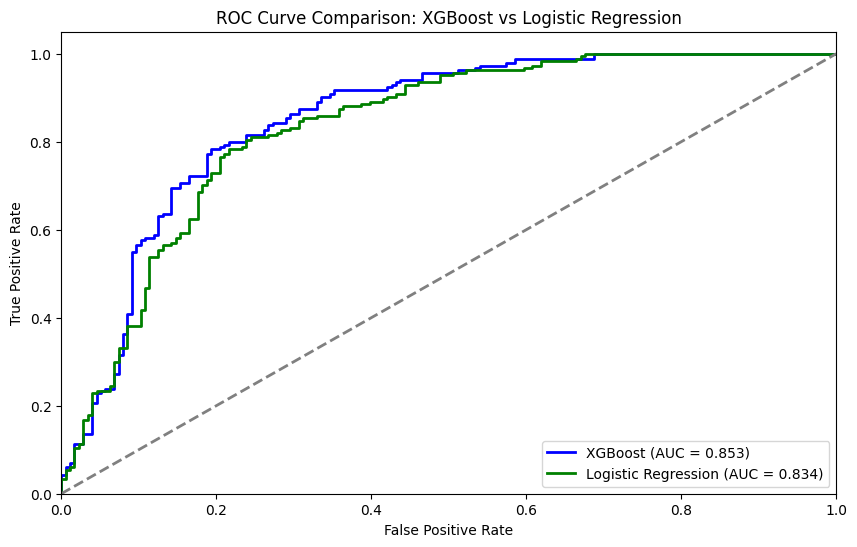

In [10]:
# Assuming that you have already trained models: `best_xgb_model` and `logreg_model`
# and you have test data: `X_test` and `y_test`

# Get the predicted probabilities for XGBoost
y_pred_prob_test_xgb = best_xgb_model.predict_proba(X_test)[:, 1]  # Predict probabilities for XGBoost

# Get the predicted probabilities for Logistic Regression
y_pred_prob_test_logreg = logreg_model.predict_proba(X_test)[:, 1]  # Predict probabilities for Logistic Regression

# Calculate the ROC curve and AUC for XGBoost
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_pred_prob_test_xgb)
roc_auc_xgb = auc(fpr_xgb, tpr_xgb)

# Calculate the ROC curve and AUC for Logistic Regression
fpr_logreg, tpr_logreg, _ = roc_curve(y_test, y_pred_prob_test_logreg)
roc_auc_logreg = auc(fpr_logreg, tpr_logreg)

# Plotting both ROC curves together
plt.figure(figsize=(10, 6))

# Plot ROC curve for XGBoost
plt.plot(fpr_xgb, tpr_xgb, color='blue', lw=2, label=f'XGBoost (AUC = {roc_auc_xgb:.3f})')

# Plot ROC curve for Logistic Regression
plt.plot(fpr_logreg, tpr_logreg, color='green', lw=2, label=f'Logistic Regression (AUC = {roc_auc_logreg:.3f})')

# Plot a diagonal line (random classifier)
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')

# Axis labels and title
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison: XGBoost vs Logistic Regression')

# Add legend
plt.legend(loc="lower right")
plt.show()
